# Step 1: Create the inventory

In [ ]:
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("../")
VIDEO_DIR = PROJECT_ROOT / "data" / "raw" / "dolos_clips"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_CSV = OUTPUT_DIR / "video_inventory.csv"

print("Project root:", PROJECT_ROOT)
print("Video directory:", VIDEO_DIR)
print("Video directory exists:", VIDEO_DIR.exists())

if not VIDEO_DIR.exists():
    raise FileNotFoundError(
        f"Can't find {VIDEO_DIR}. Set PROJECT_ROOT to the root of your project repository."
    )

Project root: ..
Video directory: ..\data\raw\dolos_clips
Video directory exists: True


In [17]:
# Find videos recursively and create one row per file.
video_paths = sorted(
    p for p in VIDEO_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".mp4"
)

rows = []
for p in video_paths:
    rows.append({
        "clip_id": p.stem,
        "file_name": p.name,
        "relative_path": str(p.relative_to(PROJECT_ROOT)),
        "size_bytes": p.stat().st_size,
    })

inventory = pd.DataFrame(rows, columns=["clip_id", "file_name", "relative_path", "size_bytes"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
inventory.to_csv(OUTPUT_CSV, index=False)

print(f"Video files found: {len(inventory):,}")
print(f"Inventory saved to: {OUTPUT_CSV}")
inventory.head(15)

Video files found: 1,361
Inventory saved to: ..\data\processed\video_inventory.csv


,clip_id,file_name,relative_path,size_bytes
0,AN_WILTY_EP15_lie10,AN_WILTY_EP15_lie10.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie10.mp4,159829
1,AN_WILTY_EP15_lie11,AN_WILTY_EP15_lie11.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie11.mp4,171344
2,AN_WILTY_EP15_lie12,AN_WILTY_EP15_lie12.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie12.mp4,229211
3,AN_WILTY_EP15_lie13,AN_WILTY_EP15_lie13.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie13.mp4,212978
4,AN_WILTY_EP15_lie14,AN_WILTY_EP15_lie14.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie14.mp4,327453
5,AN_WILTY_EP15_lie15,AN_WILTY_EP15_lie15.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie15.mp4,208954
6,AN_WILTY_EP15_lie16,AN_WILTY_EP15_lie16.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie16.mp4,384972
7,AN_WILTY_EP15_lie17,AN_WILTY_EP15_lie17.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie17.mp4,333804
8,AN_WILTY_EP15_lie18,AN_WILTY_EP15_lie18.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie18.mp4,212862
9,AN_WILTY_EP15_lie19,AN_WILTY_EP15_lie19.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie19.mp4,149743


In [18]:
# Check duplicate IDs / names. These are warnings to investigate, not automatic errors.
if inventory.empty:
    print("WARNING: no .mp4 files were found.")
else:
    duplicate_stems = inventory[inventory["clip_id"].duplicated(keep=False)].sort_values("clip_id")
    duplicate_names = inventory[inventory["file_name"].duplicated(keep=False)].sort_values("file_name")
    zero_byte = inventory[inventory["size_bytes"] == 0]

    print("Unique clip IDs:", inventory["clip_id"].nunique())
    print("Duplicate clip IDs:", len(duplicate_stems))
    print("Duplicate filenames:", len(duplicate_names))
    print("Zero-byte files:", len(zero_byte))

    if not duplicate_stems.empty:
        display(duplicate_stems)
    if not zero_byte.empty:
        display(zero_byte)

Unique clip IDs: 1361
Duplicate clip IDs: 0
Duplicate filenames: 0
Zero-byte files: 0


In [19]:
# Search common project folders for likely metadata/annotation files.
# This only lists candidates; it does not assume a file is the correct annotation source.
metadata_extensions = {".xlsx", ".xls", ".csv", ".tsv", ".txt", ".json", ".jsonl"}
search_roots = [PROJECT_ROOT / "data", PROJECT_ROOT / "configs"]
metadata_candidates = []
for root in search_roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in metadata_extensions:
                metadata_candidates.append({
                    "file_name": p.name,
                    "relative_path": str(p.relative_to(PROJECT_ROOT)),
                    "size_bytes": p.stat().st_size,
                })

metadata_df = pd.DataFrame(metadata_candidates)
if metadata_df.empty:
    print("No likely metadata files found under data/ or configs/.")
    print("Next action: retrieve the official DOLOS annotation/metadata package.")
else:
    display(metadata_df.sort_values("relative_path"))

,file_name,relative_path,size_bytes
0,dolos_transcripts.csv,data\processed\dolos_transcripts.csv,163860
1,video_inventory.csv,data\processed\video_inventory.csv,134492
2,Dolos.xlsx,data\raw\Dolos.xlsx,384584
7,female.csv,data\raw\Training_Protocols\female.csv,11552
8,long.csv,data\raw\Training_Protocols\long.csv,31189
9,male.csv,data\raw\Training_Protocols\male.csv,43306
10,short.csv,data\raw\Training_Protocols\short.csv,26909
11,test_fold1.csv,data\raw\Training_Protocols\test_fold1.csv,19254
12,test_fold2.csv,data\raw\Training_Protocols\test_fold2.csv,19439
13,test_fold3.csv,data\raw\Training_Protocols\test_fold3.csv,19258


# Part 2: Split and Transcribe


In [ ]:
from pathlib import Path
import av, pandas as pd

CLIPS_DIR = Path("../data/raw/dolos_clips")
rows = []
for p in sorted(CLIPS_DIR.glob("*.mp4")):
    try:
        with av.open(str(p)) as c: d = c.duration / 1e6
    except Exception:
        d = float("nan")
    rows.append((p.stem.replace(" ", ""), d))
dur_df = pd.DataFrame(rows, columns=["clip_id", "dur_s"])
print(dur_df.dur_s.describe().round(1))
print((dur_df.dur_s > 15).sum(), "clips > 15 s |", (dur_df.dur_s > 45).sum(), "clips > 45 s")
print(dur_df.nlargest(20, "dur_s"))

count    1361.0
mean        5.1
std         2.2
min         2.0
25%         4.0
50%         5.0
75%         6.0
max        41.0
Name: dur_s, dtype: float64
3 clips > 15 s | 0 clips > 45 s
                      clip_id      dur_s
389     BRI_WILTY_EP61_lie_36  41.000000
919        SB_WILTY_EP34_lie8  19.000000
1016      SB_WILTY_EP42_lie15  16.000000
902        SB_WILTY_EP33_lie5  14.000000
990      SB_WILTY_EP38_truth3  14.000000
773        LS_WILTY_EP72_lie6  12.000000
972     SB_WILTY_EP37_truth13  12.000000
985        SB_WILTY_EP38_lie4  12.000000
1034    SB_WILTY_EP42_truth14  12.000000
1024       SB_WILTY_EP42_lie5  11.560000
517   BRI_WILTY_EP66_truth_15  11.020835
778       LS_WILTY_EP72_true2  11.000000
898        SB_WILTY_EP33_lie1  11.000000
925      SB_WILTY_EP34_truth5  11.000000
986        SB_WILTY_EP38_lie5  11.000000
1028       SB_WILTY_EP42_lie9  11.000000
993       SB_WILTY_EP41_lie11  10.010000
25        AN_WILTY_EP16_lie17  10.000000
192       AN_WILTY_EP24_lie16  10

In [22]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit


INPUT_CSV = Path("../data/processed/video_inventory.csv")
OUTPUT_CSV = Path("../data/splits/subject_isolated_splits.csv")

def create_zero_leakage_splits():
    # 1. Load the dataset
    df = pd.read_csv(INPUT_CSV)
    
    # 2. Extract Subject Identity
    # Converts 'AN_WILTY_EP15_lie10' -> 'AN_WILTY_EP15'
    df['subject_id'] = df['clip_id'].apply(lambda x: "_".join(str(x).split('_')[:-1]))
    
    print(f"Total Clips: {len(df)}")
    print(f"Unique Subjects/Episodes: {df['subject_id'].nunique()}")

    # 3. First Split: Separate Train (70%) vs Temp (30%)
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    train_idx, temp_idx = next(gss1.split(df, groups=df['subject_id']))
    
    # 4. Second Split: Separate Temp into Val (15%) and Test (15%)
    temp_df = df.iloc[temp_idx].copy()
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    val_idx_temp, test_idx_temp = next(gss2.split(temp_df, groups=temp_df['subject_id']))
    
    # Map temp indices back to original dataframe
    val_idx = temp_idx[val_idx_temp]
    test_idx = temp_idx[test_idx_temp]

    # Assign split labels
    df.loc[train_idx, 'split'] = 'train'
    df.loc[val_idx, 'split'] = 'val'
    df.loc[test_idx, 'split'] = 'test'

    # Display split statistics
    print("\n--- Split Statistics ---")
    print(df['split'].value_counts())
    print("\n--- Unique Subjects per Split ---")
    print(df.groupby('split')['subject_id'].nunique())

    # Save mapping
    OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\nZero-leakage splits saved to: {OUTPUT_CSV}")

if __name__ == "__main__":
    create_zero_leakage_splits()

Total Clips: 1361
Unique Subjects/Episodes: 75

--- Split Statistics ---
split
train    948
test     221
val      192
Name: count, dtype: int64

--- Unique Subjects per Split ---
split
test     12
train    52
val      11
Name: subject_id, dtype: int64

Zero-leakage splits saved to: ..\data\splits\subject_isolated_splits.csv


In [ ]:
import pandas as pd
df = pd.read_csv(OUTPUT_CSV)
train_df = df[df['split'] == 'train'].copy()
print(f"EDA restricted to {len(train_df)} training clips.")

EDA restricted to 948 training clips.


## Generate Transcription

In [28]:
from pathlib import Path
import pandas as pd
import torch
import os
from tqdm import tqdm
from faster_whisper import WhisperModel
import av
import av.container
from concurrent.futures import ThreadPoolExecutor, as_completed

CLIPS_DIR = Path("../data/raw/dolos_clips")
OUTPUT_CSV = Path("../data/processed/dolos_transcripts.csv")

# PyTorch DLL workaround
torch_lib_path = os.path.join(os.path.dirname(torch.__file__), "lib")
if os.path.exists(torch_lib_path):
    os.add_dll_directory(torch_lib_path)

# =========================================================
# RECURSION-PROOF PATCH: Bypasses memory pollution by
# binding directly to the underlying C-extension function.
# =========================================================
_c_extension_open = av.container.open

def _safe_av_open(*args, **kwargs):
    kwargs.pop("metadata_errors", None)
    return _c_extension_open(*args, **kwargs)

av.open = _safe_av_open
# =========================================================

# Use CPU backend
device = "cpu"
compute_type = "int8"

print(f"Running on device: {device.upper()} (precision: {compute_type})")

# Load faster-whisper model with Multi-Threading Config
print("Loading Whisper 'small' model...")
model = WhisperModel(
    "small", 
    device=device, 
    compute_type=compute_type,
    cpu_threads=2,    # Threads allocated per worker
    num_workers=6     # Number of parallel video workers
)

video_files = sorted(list(CLIPS_DIR.glob("*.mp4")))
print(f"Found {len(video_files)} video clips to process.")

# Resume check for existing outputs
processed_files = set()
records = []
if OUTPUT_CSV.exists():
    try:
        existing_df = pd.read_csv(OUTPUT_CSV)
        records = existing_df.to_dict("records")
        processed_files = set(existing_df["file_name"].dropna().tolist())
        print(f"Resuming session: {len(processed_files)} clips already transcribed.")
    except Exception:
        records = []

# Filter out files that are already processed
pending_files = [v for v in video_files if v.name not in processed_files]

def process_clip(video_path):
    try:
        # Transcribe directly from .mp4, enforcing English
        segments, info = model.transcribe(
            str(video_path), 
            beam_size=5, 
            vad_filter=True,  # Filter out non-speech segments
            language="en"     # Force English to prevent language drift
        )
        full_text = " ".join([segment.text.strip() for segment in segments]).strip()
        return {
            "status": "success",
            "file_name": video_path.name,
            "transcript": full_text
        }
    except Exception as e:
        return {"status": "error", "file_name": video_path.name, "error": str(e)}

# Parallel processing loop
new_count = 0
if pending_files:
    with ThreadPoolExecutor(max_workers=6) as executor:
        futures = [executor.submit(process_clip, v) for v in pending_files]
        
        for future in tqdm(as_completed(futures), total=len(futures), desc="Transcribing (CPU Parallel)"):
            result = future.result()
            
            if result["status"] == "success":
                records.append({
                    "file_name": result["file_name"],
                    "transcript": result["transcript"]
                })
                new_count += 1
                
                # Checkpoint save every 50 files
                if new_count % 50 == 0:
                    OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
                    pd.DataFrame(records).to_csv(OUTPUT_CSV, index=False)
            else:
                print(f"\nError processing {result['file_name']}: {result['error']}")

# Final save
OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame(records).to_csv(OUTPUT_CSV, index=False)
print(f"\nTranscription complete. Total records saved: {len(records)} -> {OUTPUT_CSV}")

Running on device: CPU (precision: int8)
Loading Whisper 'small' model...
Found 1361 video clips to process.


Transcribing (CPU Parallel):  76%|███████▋  | 1040/1361 [23:31<04:44,  1.13it/s]


Error processing SB_WILTY_EP42_truth9.mp4: tuple index out of range


Transcribing (CPU Parallel): 100%|██████████| 1361/1361 [30:44<00:00,  1.35s/it]


Transcription complete. Total records saved: 1360 -> ..\data\processed\dolos_transcripts.csv


## Generate Max L

clips with no transcript row: 0
Empty DataFrame
Columns: [clip_id, split]
Index: []
Analyzing 1088 training clips
{0.5: 17.0, 0.9: 33.0, 0.95: 38.0, 0.99: 50.5} | max: 143
clips truncated at L=56: 0.92%
clips with <3 words: 0.4%


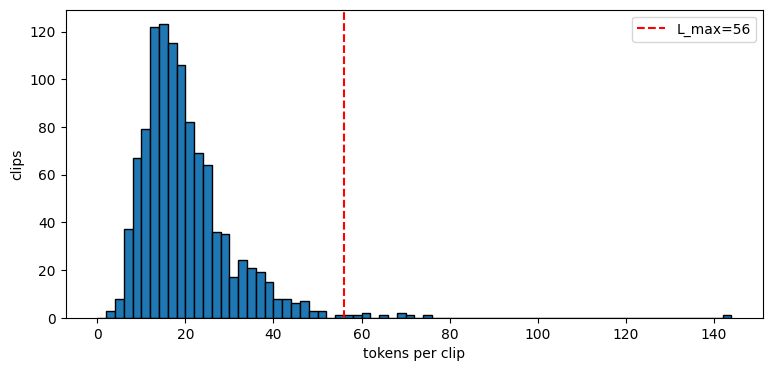

In [30]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import sentencepiece as spm
from huggingface_hub import hf_hub_download

SPLITS_CSV      = Path("../data/splits/subject_isolated_splits.csv")
TRANSCRIPTS_CSV = Path("../data/processed/dolos_transcripts.csv")

splits_df = pd.read_csv(SPLITS_CSV)
tr = pd.read_csv(TRANSCRIPTS_CSV)
tr["clip_id"] = (tr["file_name"].str.replace(r"\.mp4$", "", regex=True)
                                 .str.replace(r"\s+", "", regex=True))
tr["transcript"] = tr["transcript"].fillna("").astype(str)

df = splits_df.merge(tr[["clip_id", "transcript"]], on="clip_id", how="left")
print("clips with no transcript row:", df["transcript"].isna().sum())   # expect 2, you got 6 earlier
print(df.loc[df["transcript"].isna(), ["clip_id", "split"]])
df["transcript"] = df["transcript"].fillna("")

train_df = df[df["split"] == "train"].copy()
print(f"Analyzing {len(train_df)} training clips")

spm_path = hf_hub_download("microsoft/deberta-v3-base", "spm.model")
sp = spm.SentencePieceProcessor(model_file=spm_path)
train_df["token_count"] = train_df["transcript"].apply(lambda t: len(sp.encode(t)))   # no special tokens

q = train_df["token_count"].quantile([.5, .9, .95, .99])
L = int(np.ceil(q[.99] / 8) * 8)                                    # round up to a multiple of 8
print(q.round(1).to_dict(), "| max:", train_df["token_count"].max())
print(f"clips truncated at L={L}: {(train_df.token_count > L).mean()*100:.2f}%")
print(f"clips with <3 words: {(train_df.transcript.str.split().str.len() < 3).mean()*100:.1f}%")

plt.figure(figsize=(9, 4))
plt.hist(train_df["token_count"], bins=range(0, train_df.token_count.max() + 3, 2), edgecolor="black")
plt.axvline(L, color="red", ls="--", label=f"L_max={L}")
plt.xlabel("tokens per clip"); plt.ylabel("clips"); plt.legend(); plt.show()

# Transcription EDA

[nltk_data] Downloading package stopwords to C:\Users\BLU-
[nltk_data]     RAY\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


--- Running Spell Checker ---
Found 218 potentially misspelled words or transcription artifacts out of 2916 unique words.
Most frequent unknown/misspelled words: [('im', 62), ('dont', 60), ('didnt', 40), ('thats', 34), ('ive', 34), ('wasnt', 27), ('theres', 23), ('youre', 15), ('wouldnt', 10), ('doesnt', 9), ('youve', 9), ('theyre', 8), ('isnt', 7), ('youd', 6), ('theyd', 6), ('werent', 5), ('hed', 5), ('couldnt', 5), ('hadnt', 5), ('weve', 4)]


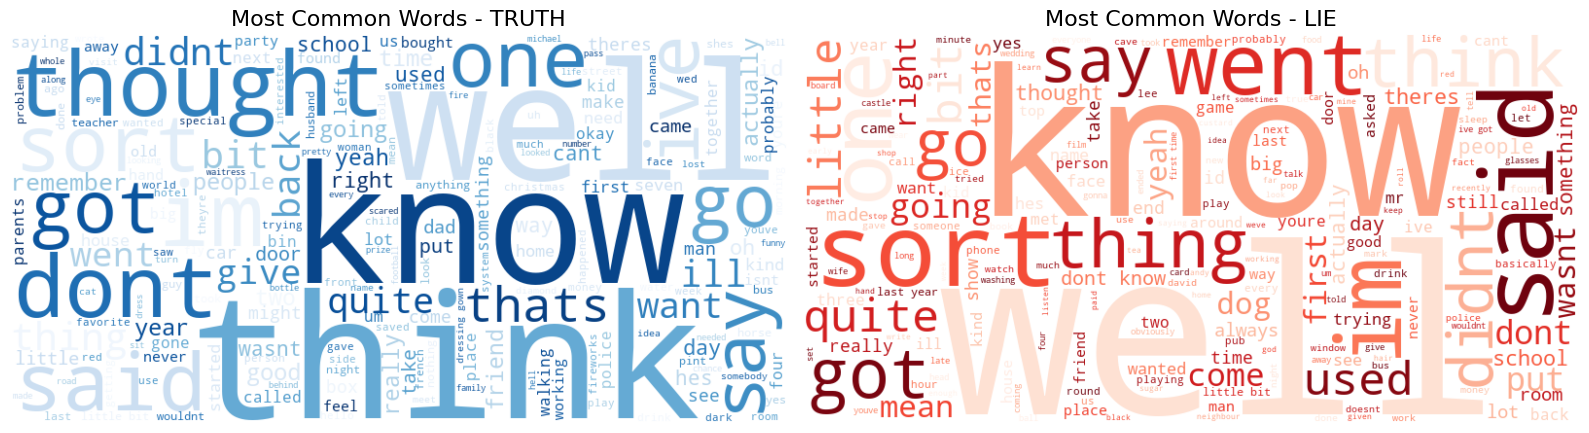

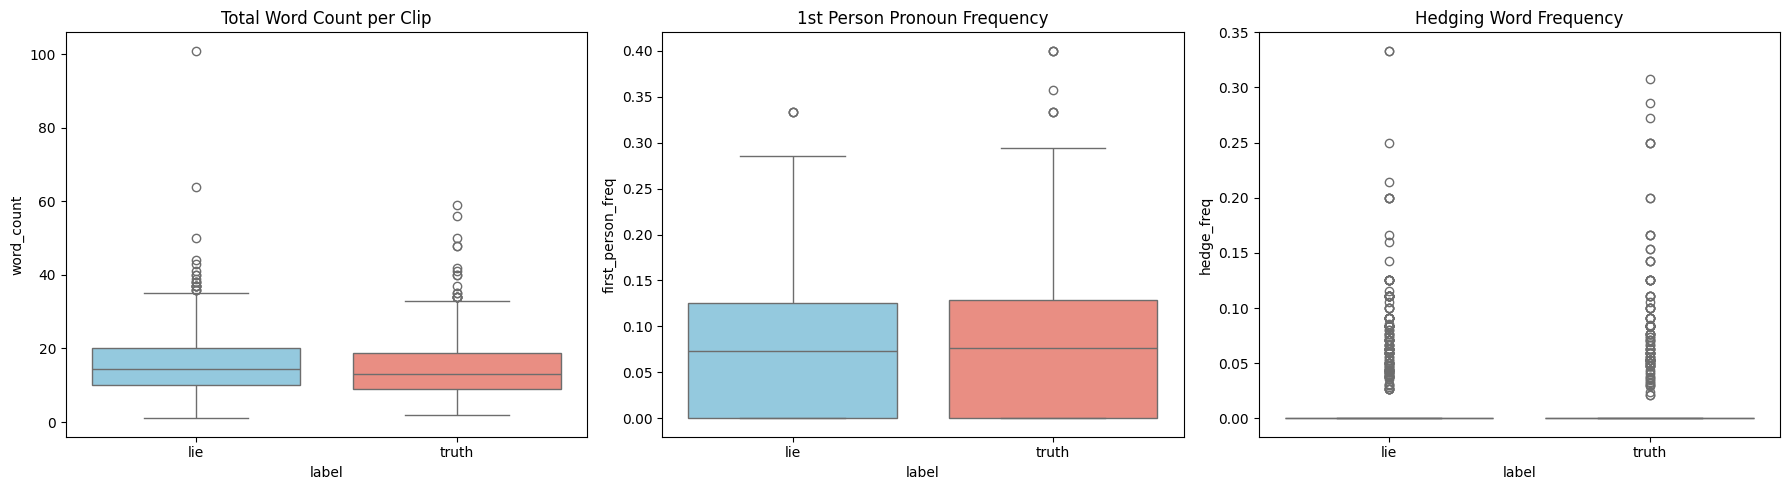


--- Psycholinguistic Feature Means ---
       word_count  first_person_freq  hedge_freq
label                                           
lie       16.2407             0.0788      0.0199
truth     14.8968             0.0835      0.0196


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from wordcloud import WordCloud
from spellchecker import SpellChecker
from collections import Counter
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

# 1. Load Data & Extract Labels (Strictly on Train Split)
SPLITS_CSV = "../data/splits/subject_isolated_splits.csv"
TRANSCRIPTS_CSV = "../data/processed/dolos_transcripts.csv"

splits_df = pd.read_csv(SPLITS_CSV)
tr = pd.read_csv(TRANSCRIPTS_CSV)

# Clean clip_id to match splits
tr["clip_id"] = tr["file_name"].str.replace(r"\.mp4$", "", regex=True).str.replace(r"\s+", "", regex=True)
df = splits_df.merge(tr[["clip_id", "transcript"]], on="clip_id", how="left")
df["transcript"] = df["transcript"].fillna("").astype(str)

# Isolate training data
train_df = df[df["split"] == "train"].copy()

# Extract the ground truth label from the clip_id suffix
train_df['label'] = train_df['clip_id'].apply(lambda x: 'lie' if 'lie' in x.lower() else 'truth')

# 2. Text Preprocessing
stop_words = set(stopwords.words('english'))

def get_clean_tokens(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text) # Remove punctuation
    return text.split()

train_df['tokens'] = train_df['transcript'].apply(get_clean_tokens)
train_df['clean_tokens'] = train_df['tokens'].apply(lambda x: [w for w in x if w not in stop_words])

# 3. Spelling Checker on Vocabulary
print("--- Running Spell Checker ---")
spell = SpellChecker()
all_tokens = [word for tokens in train_df['tokens'] for word in tokens]
unique_words = set(all_tokens)

# Find misspelled words (this catches Whisper hallucinations or heavy filler words)
misspelled = spell.unknown(unique_words)
print(f"Found {len(misspelled)} potentially misspelled words or transcription artifacts out of {len(unique_words)} unique words.")
# Display top 20 most frequent unknown words
unknown_freq = Counter([w for w in all_tokens if w in misspelled])
print("Most frequent unknown/misspelled words:", unknown_freq.most_common(20))

# 4. Word Clouds per Class
truth_words = [word for tokens in train_df[train_df['label'] == 'truth']['clean_tokens'] for word in tokens]
lie_words = [word for tokens in train_df[train_df['label'] == 'lie']['clean_tokens'] for word in tokens]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
wc_truth = WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate(" ".join(truth_words))
axes[0].imshow(wc_truth, interpolation='bilinear')
axes[0].set_title('Most Common Words - TRUTH', fontsize=16)
axes[0].axis('off')

wc_lie = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(" ".join(lie_words))
axes[1].imshow(wc_lie, interpolation='bilinear')
axes[1].set_title('Most Common Words - LIE', fontsize=16)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# 5. Psycholinguistic Deception Markers
# Deception literature identifies specific word usage patterns in liars
first_person = set(['i', 'me', 'my', 'mine', 'we', 'us', 'our', 'ours'])
hedges = set(['maybe', 'think', 'probably', 'might', 'could', 'guess', 'sort', 'kind', 'well', 'uh', 'um', 'basically', 'actually'])

train_df['word_count'] = train_df['tokens'].apply(len)
train_df['first_person_count'] = train_df['tokens'].apply(lambda x: sum(1 for w in x if w in first_person))
train_df['hedge_count'] = train_df['tokens'].apply(lambda x: sum(1 for w in x if w in hedges))

# Normalize frequencies by total word count to prevent bias from longer clips
train_df['first_person_freq'] = train_df['first_person_count'] / train_df['word_count'].replace(0, 1)
train_df['hedge_freq'] = train_df['hedge_count'] / train_df['word_count'].replace(0, 1)

# Plotting Psycholinguistic Features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=train_df, x='label', y='word_count', hue='label', ax=axes[0], palette=['skyblue', 'salmon'], legend=False)
axes[0].set_title('Total Word Count per Clip')

sns.boxplot(data=train_df, x='label', y='first_person_freq', hue='label', ax=axes[1], palette=['skyblue', 'salmon'], legend=False)
axes[1].set_title('1st Person Pronoun Frequency')

sns.boxplot(data=train_df, x='label', y='hedge_freq', hue='label', ax=axes[2], palette=['skyblue', 'salmon'], legend=False)
axes[2].set_title('Hedging Word Frequency')

plt.tight_layout()
plt.show()

# Print statistical means
print("\n--- Psycholinguistic Feature Means ---")
print(train_df.groupby('label')[['word_count', 'first_person_freq', 'hedge_freq']].mean().round(4))

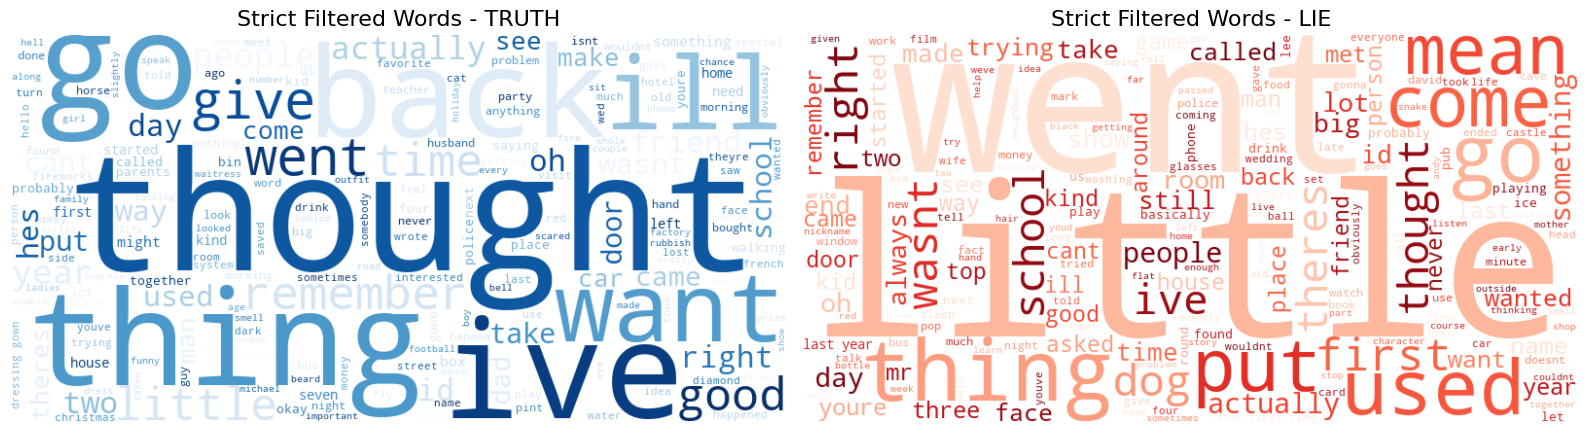

In [2]:
# 6. Strict Filtering Word Clouds (Removing Conversational Fillers)
# Define the custom fillers observed in the initial word clouds
custom_fillers = {
    'well', 'know', 'think', 'sort', 'said', 'one', 'got', 
    'didnt', 'dont', 'going', 'really', 'say', 'yeah', 'uh', 
    'um', 'im', 'thats', 'bit', 'quite', 'just', 'like', 'yes', 'no'
}

# Combine with the existing NLTK stopwords
extended_stop_words = stop_words.union(custom_fillers)

# Create a new column to preserve the original clean_tokens
train_df['strict_clean_tokens'] = train_df['tokens'].apply(
    lambda x: [w for w in x if w not in extended_stop_words]
)

# Extract the newly filtered words per class
strict_truth_words = [word for tokens in train_df[train_df['label'] == 'truth']['strict_clean_tokens'] for word in tokens]
strict_lie_words = [word for tokens in train_df[train_df['label'] == 'lie']['strict_clean_tokens'] for word in tokens]

# Plot the Strict Filtered Word Clouds
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

wc_truth_strict = WordCloud(
    width=800, height=400, background_color='white', colormap='Blues'
).generate(" ".join(strict_truth_words))
axes[0].imshow(wc_truth_strict, interpolation='bilinear')
axes[0].set_title('Strict Filtered Words - TRUTH', fontsize=16)
axes[0].axis('off')

wc_lie_strict = WordCloud(
    width=800, height=400, background_color='white', colormap='Reds'
).generate(" ".join(strict_lie_words))
axes[1].imshow(wc_lie_strict, interpolation='bilinear')
axes[1].set_title('Strict Filtered Words - LIE', fontsize=16)
axes[1].axis('off')

plt.tight_layout()
plt.show()